In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('Libraries imported successfully')



Libraries imported successfully


In [5]:
df = pd.read_csv('Cleaned_Dataset.csv')
print(df.to_string())
print('Dataset loaded successfully')

      Unnamed: 0 show_id     type                                                                                                     title                                                                                                                                                                                                          director               country  date_added  release_year    rating    duration                                                                        listed_in
0              0      s1    Movie                                                                                      Dick Johnson Is Dead                                                                                                                                                                                                   Kirsten Johnson         United States   9/25/2021          2020     PG-13      90 min                                                                    Documentarie

In [29]:
print(df.head())

   Unnamed: 0 show_id     type                             title  \
0           0      s1    Movie              Dick Johnson Is Dead   
1           1      s3  TV Show                         Ganglands   
2           2      s6  TV Show                     Midnight Mass   
3           3     s14    Movie  Confessions of an Invisible Girl   
4           4      s8    Movie                           Sankofa   

          director        country date_added  release_year rating  duration  \
0  Kirsten Johnson  United States  9/25/2021          2020  PG-13    90 min   
1  Julien Leclercq         France  9/24/2021          2021  TV-MA  1 Season   
2    Mike Flanagan  United States  9/24/2021          2021  TV-MA  1 Season   
3    Bruno Garotti         Brazil  9/22/2021          2021  TV-PG    91 min   
4     Haile Gerima  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Cri

Print the Shape of the Dataset.

In [30]:
print(df.shape[0])
print(df.shape[1])

8790
11


Show the column of the Dataset in form of a List

In [31]:
print(df.columns.tolist())

['Unnamed: 0', 'show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


In [32]:
print(df.dtypes)

Unnamed: 0      int64
show_id           str
type              str
title             str
director          str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
dtype: object


In [33]:
print(df.isnull().sum())

Unnamed: 0      0
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [34]:
print(df.describe(include='all'))

         Unnamed: 0 show_id   type  title   director        country  \
count   8790.000000    8790   8790   8790       8790           8790   
unique          NaN    8790      2   8786       4528             86   
top             NaN      s1  Movie  9-Feb  Not Given  United States   
freq            NaN       1   6126      2       2588           3240   
mean    4394.500000     NaN    NaN    NaN        NaN            NaN   
std     2537.598767     NaN    NaN    NaN        NaN            NaN   
min        0.000000     NaN    NaN    NaN        NaN            NaN   
25%     2197.250000     NaN    NaN    NaN        NaN            NaN   
50%     4394.500000     NaN    NaN    NaN        NaN            NaN   
75%     6591.750000     NaN    NaN    NaN        NaN            NaN   
max     8789.000000     NaN    NaN    NaN        NaN            NaN   

       date_added  release_year rating  duration                     listed_in  
count        8790   8790.000000   8790      8790                  

In [35]:
print(df.duplicated().sum())

0


In [36]:
print(df['type'].value_counts())
print(df['type'])

type
Movie      6126
TV Show    2664
Name: count, dtype: int64
0         Movie
1       TV Show
2       TV Show
3         Movie
4         Movie
         ...   
8785    TV Show
8786    TV Show
8787    TV Show
8788    TV Show
8789    TV Show
Name: type, Length: 8790, dtype: str


In [37]:
type_counts = df['type'].value_counts(normalize=True) * 100
print(type_counts)

type
Movie      69.692833
TV Show    30.307167
Name: proportion, dtype: float64


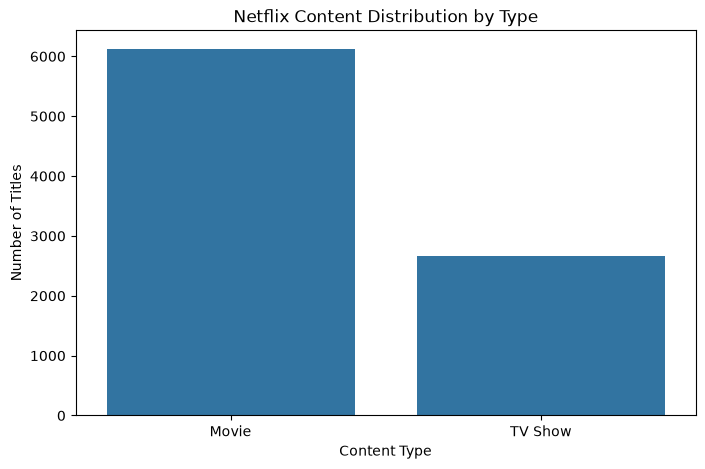

In [38]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='type')

plt.title('Netflix Content Distribution by Type')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.show()

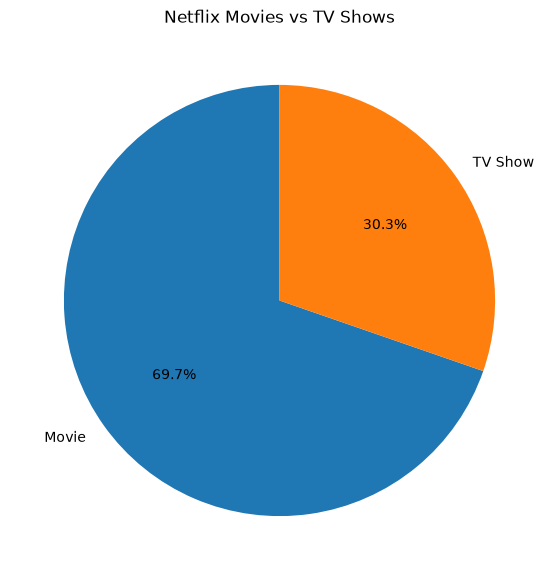

In [39]:
plt.figure(figsize=(7, 7))

type_counts.plot(
    kind='pie',
    autopct= '%1.1f%%',
    startangle=90
)

plt.title('Netflix Movies vs TV Shows')
plt.ylabel('')
plt.show()

In [10]:
top_countries = df['country'].value_counts().head()

print(top_countries)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64


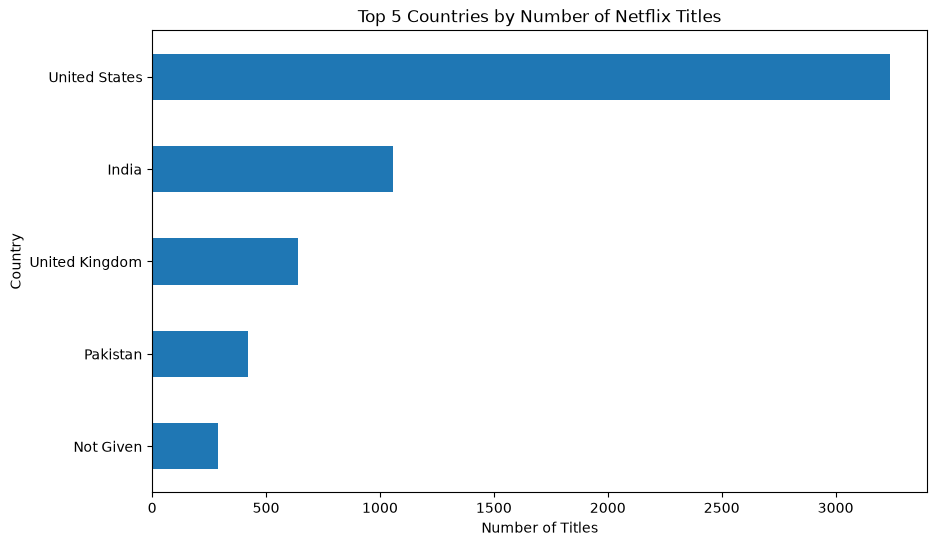

In [12]:
plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(kind='barh')

plt.title('Top 5 Countries by Number of Netflix Titles')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

In [42]:
genres = df['listed_in'].dropna().str.split(',').explode()
top_genres = genres.value_counts().head(10)
print(top_genres)

listed_in
 International Movies     2624
Dramas                    1599
Comedies                  1210
Action & Adventure         859
Documentaries              829
 Dramas                    827
International TV Shows     773
 Independent Movies        736
 TV Dramas                 695
 Romantic Movies           613
Name: count, dtype: int64


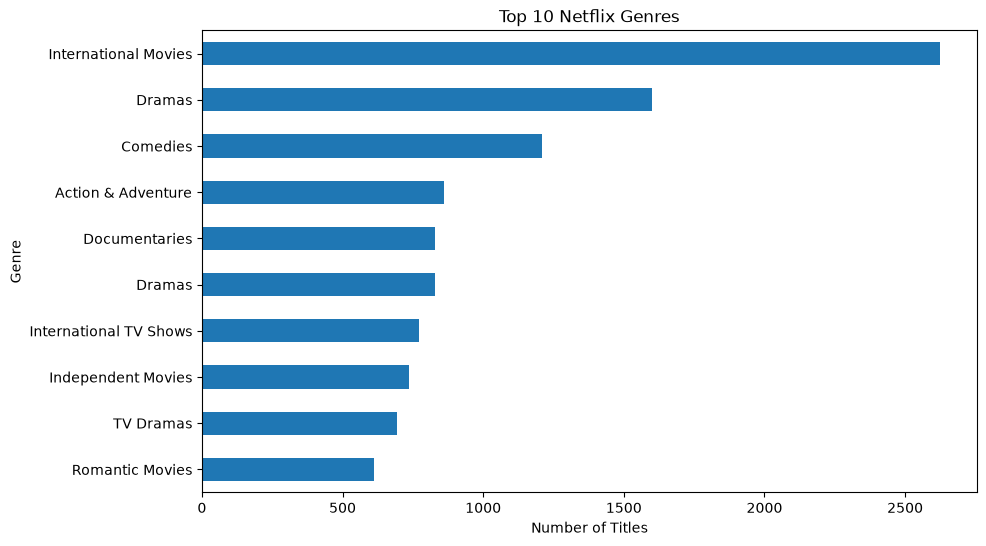

In [45]:
plt.figure(figsize=(10, 6))
top_genres.sort_values().plot(kind='barh')
plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

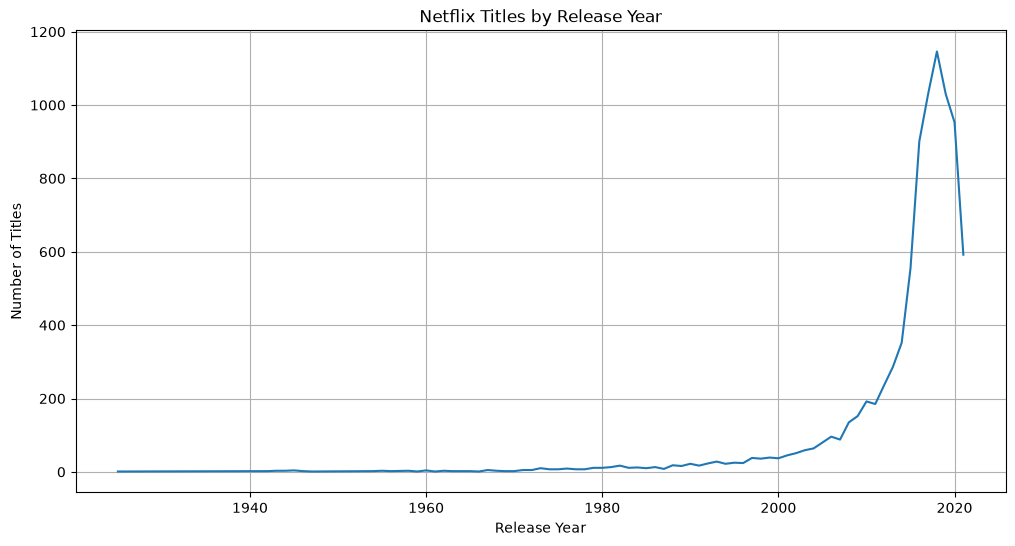

In [47]:
release_year_counts = df['release_year'].value_counts().sort_index()

plt.figure(figsize=(12,6))

plt.plot(
    release_year_counts.index,
    release_year_counts.values
)

plt.title('Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)

plt.show()

<Figure size 1200x600 with 0 Axes>

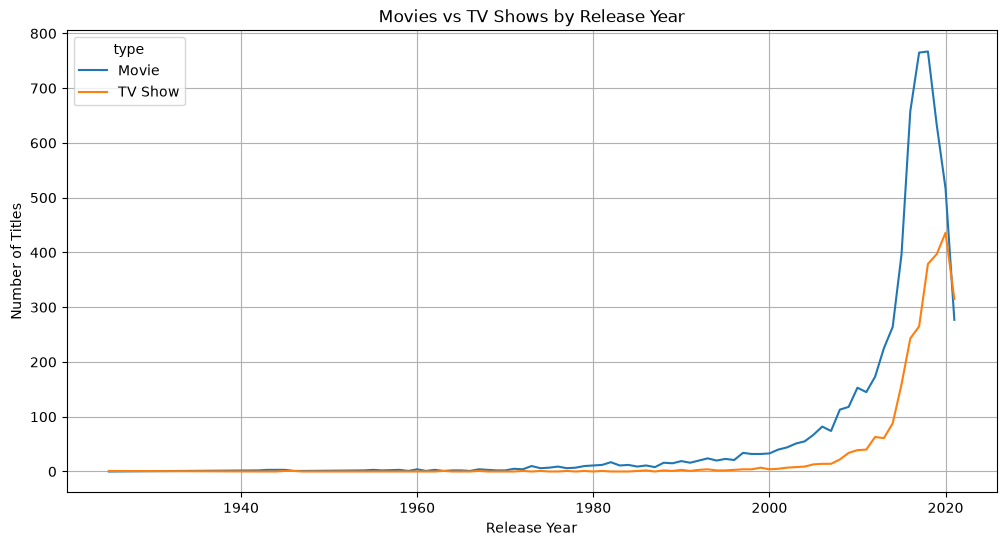

In [13]:
year_type = pd.crosstab(
    df['release_year'],
    df['type']
)

plt.figure(figsize=(12, 6))
year_type.plot(figsize=(12, 6))

plt.title('Movies vs TV Shows by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid('True')
plt.show()

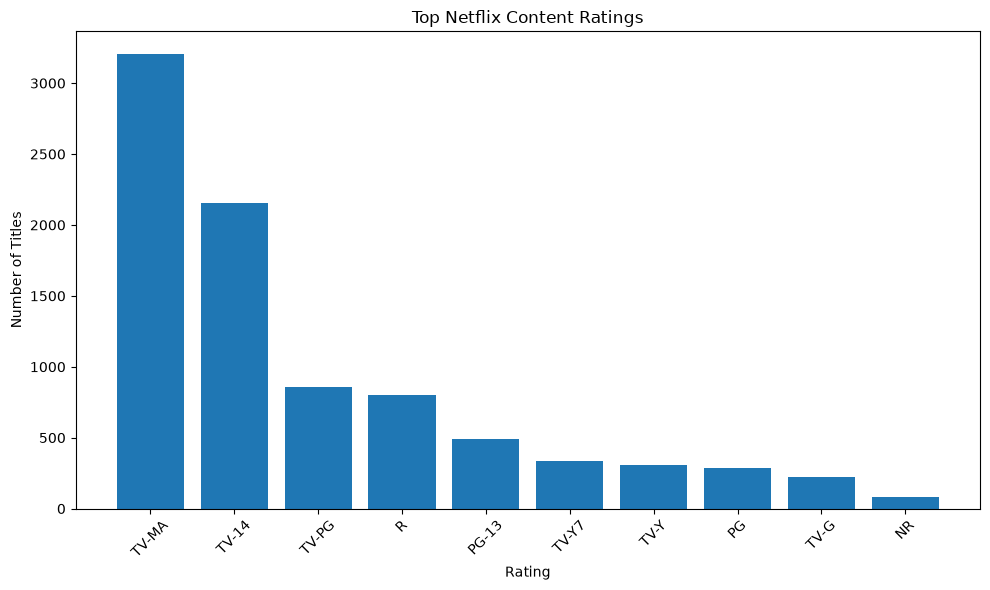

In [55]:
rating_counts = df['rating'].value_counts().head(10)
plt.figure(figsize=(10, 6))
plt.bar(rating_counts.index,
        rating_counts.values)

plt.title('Top Netflix Content Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [54]:
movie_duration = (
    df[df['type']== 'Movie']['duration']
    .dropna()
    .str.extract(r'(\d+)')
    .astype(float)
)

print(movie_duration[0].mean())
print(movie_duration[0].min())
print(movie_duration[0].max())

99.58488410055502
3.0
312.0


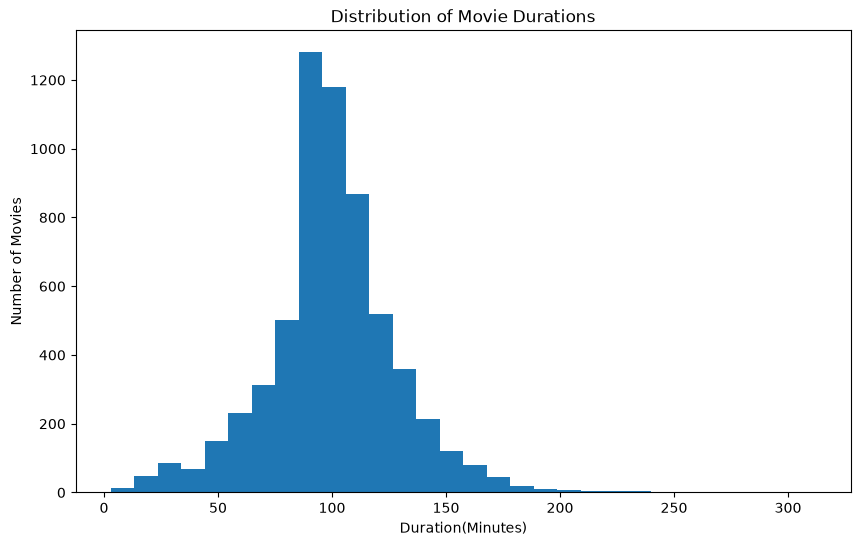

In [52]:
plt.figure(figsize=(10, 6))
plt.hist(movie_duration[0], bins=30)

plt.title('Distribution of Movie Durations')
plt.xlabel('Duration(Minutes)')
plt.ylabel('Number of Movies')

plt.show()